> **언어 전환 & 바로가기**: **🇰🇷 한국어 (현재 폴더: `notebooks/ko/`)** · [🇺🇸 English (`notebooks/en/stage2_wiki_and_semantic_graph_en.ipynb`)](../en/stage2_wiki_and_semantic_graph_en.ipynb) ｜ [방법론 가이드 (Methodology Doc)](../../methodology/ko/02_stage2_wiki_and_semantic_graph_ko.md) ｜ [노트북 전체 인덱스 (README)](../README.md) ｜ [라이브 스튜디오 탭 열기](https://agentic-ontology-starter-lwrlf7yogq-du.a.run.app/?tab=stage2)
>
> **전체 라이프사이클 네비게이션**: [0. 전체 흐름 개요](./stage0_overview_walkthrough_ko.ipynb) → [Stage 1 · 준비·분석](./stage1_asset_and_cq_ko.ipynb) → **[▶ Stage 2 · 파싱·통합](./stage2_wiki_and_semantic_graph_ko.ipynb)** → [Stage 3 · 그래프 구축](./stage3_property_graph_bigquery_spanner_ko.ipynb) → [Stage 4 · 에이전트·답변](./stage4_agent_and_mcp_execution_ko.ipynb) → [Stage 5 · 리니지·검증](./stage5_lineage_and_evaluation_ko.ipynb)

---

# Stage 2. [파싱 & 통합] Ready-to-Use 3-Layer OKF 위키 · 비즈니스 규칙/워크플로(`W1~W3`) & 시맨틱 그래프 연결
## Step 2.1 SHA-256 해시 앵커 청크 및 OKF v0.2 3-Layer Wiki 연결 · Step 2.2 도메인 규칙 및 시맨틱 그래프 통합 (`Entity=Node`, `Concept=Edge`)

Stage 2는 방법론의 **Phase 3(파싱)**과 **Phase 4(통합)** 결과로 프로비저닝된 **Ready-to-Use 지식 리소스**에 연결합니다. 원시 정책 가이드(`01_guides/*.md`)가 문단 단위(`DOC_CHUNK_001~005`) **결정론적 SHA-256 해시 앵커(`anchor_<12hex>`)**로 파싱되어 있고, **Andrej Karpathy 3-Layer LLM-Wiki(`summary.md`, `entities.md`, `concepts.md`, `rules.md`)**, **비즈니스 규칙 4종(`business_rules.json`) · 워크플로 3종(`business_workflows.json`, `W1~W3`)**, 그리고 **시맨틱 온톨로지 그래프(`ontology.jsonld`, `tb_domain_rules`, `edge_rule_applies_to_plan`)**가 GCS(`gs://seanjung-poc-starter-ontology/ontology/`)와 BigQuery에 준비되어 있어 `stage2_resource_check`로 즉시 검증합니다.

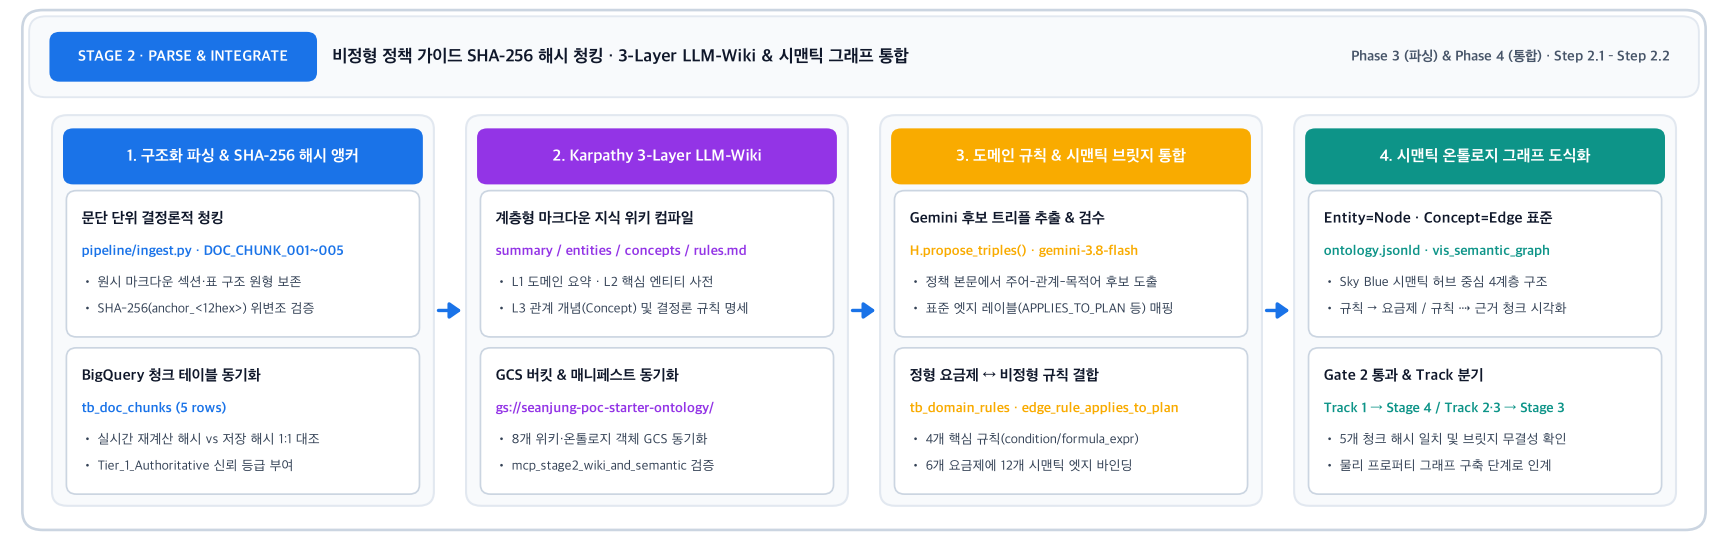


In [ ]:
%load_ext bigframes
import sys
from pathlib import Path
for _p in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
    if (_p / "nb_helpers.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
H.setup("ko")
server = DomainMcpServer()


### 1. [Phase 3a: 파싱 (Parsing)] 원시 정책 마크다운(`01_guides/*.md`) 정규식 청크 분할 및 SHA-256 해시 앵커 무결성 대조 (`H.parse_guides_live_demo`)


In [ ]:
df_parsed = H.parse_guides_live_demo()
H.show(df_parsed)


In [ ]:
%%bqsql df_bq_chunks
SELECT chunk_id, source_file, section_title, trust_tier, content_sha256,
       CHAR_LENGTH(content) AS char_len, SUBSTR(content, 1, 85) AS content_preview
FROM `seanjung-poc.starter_ontology_dw.tb_doc_chunks`
ORDER BY chunk_id


In [ ]:
H.show(df_bq_chunks)


### 2. [Phase 3b: 위키 컴파일 & GCS 동기화] Andrej Karpathy 3-Layer LLM-Wiki (`summary.md`, `entities.md`, `concepts.md`, `rules.md`) 및 `stage2_resource_check` 리소스 검증


In [ ]:
df_wiki, manifest = H.wiki_compilation_summary()
H.md(f"**GCS Manifest Status**: `{manifest['status']}` · Bucket `{manifest['gcs_uri']}` · Uploaded Objects `{len(manifest['uploaded_gcs_objects'])}` · Loaded BQ Tables `{manifest['validation']['bigquery_tables_loaded']}`")
H.show(df_wiki)
for fname in ("summary.md", "entities.md", "concepts.md", "rules.md"):
    H.show_md_file(H.ROOT / "data/llm_wiki/ko" / fname, max_lines=22)
res_s2 = server.execute_tool("stage2_resource_check", {"steps": ["compile_3layer_wiki", "extract_hash_anchors", "bind_semantic_bridges"]})
H.show_tool(res_s2, "anchored_chunks")


### 3. [Phase 4a: 시맨틱 통합 (Integration)] Vertex AI Gemini(`gemini-3.8-flash`) 기반 후보 트리플 추출 및 도메인 규칙 ↔ 요금제 시맨틱 브릿지 테이블 확인 (`%%bqsql`)


In [ ]:
triples = H.propose_triples(["DOC_CHUNK_001", "DOC_CHUNK_003", "DOC_CHUNK_004"])
H.show(triples)


In [ ]:
%%bqsql df_rules
SELECT r.rule_id,
       r.rule_name AS rule_name,
       r.rule_category, r.condition_expr, r.formula_expr,
       r.source_chunk_id, c.section_title, c.content_sha256
FROM `seanjung-poc.starter_ontology_dw.tb_domain_rules` r
JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` c ON c.chunk_id = r.source_chunk_id
ORDER BY r.rule_id


In [ ]:
%%bqsql df_rule_plan
SELECT e.edge_id, e.rule_id, e.plan_id, p.plan_name, p.monthly_fee_krw,
       e.relation_label_ko AS relation_label_ko,
       e.source_chunk_id
FROM `seanjung-poc.starter_ontology_dw.edge_rule_applies_to_plan` e
JOIN `seanjung-poc.starter_ontology_dw.tb_plan_master` p USING (plan_id)
ORDER BY e.rule_id, p.monthly_fee_krw DESC


In [ ]:
H.show(df_rules)
H.show(df_rule_plan)


### 4. [Phase 4b: 시맨틱 그래프 설계 및 도식화] OKF v0.2 `ontology.jsonld` 명세 및 시맨틱 온톨로지 그래프 (`Entity=Node`, `Concept=Edge`)


In [ ]:
ont = H.read_json("data/output/ontology.jsonld")
H.show(pd.DataFrame(ont.get("@graph", [])))
H.draw_semantic_design_graph()

rp = H.pdf(df_rule_plan)
nodes, edges = [], []
for r in rp.itertuples():
    nodes.append({"id": r.source_chunk_id, "name": r.source_chunk_id, "color": "#9334E6", "layer": 0})
    nodes.append({"id": r.rule_id, "name": r.rule_id, "color": "#F9AB00", "layer": 1})
    nodes.append({"id": r.plan_name, "name": r.plan_name, "color": "#0284c7", "layer": 2})
    e_lbl = r.relation_label_ko if H.LANG == "ko" else "APPLIES_TO_PLAN"
    edges.append({"src": r.rule_id, "dst": r.plan_name, "label": e_lbl})
    edges.append({"src": r.rule_id, "dst": r.source_chunk_id, "label": "GROUNDED_IN", "style": "dashed"})
uniq_nodes = list({n["id"]: n for n in nodes}.values())
H.draw_graph(uniq_nodes, edges,
             "BigQuery 실데이터 기반 DocChunk ⇠ Rule (GROUNDED_IN) 및 Rule → Plan (APPLIES_TO_PLAN) 시맨틱 브릿지 그래프",
             layout="layers", figsize=(11.8, 5.4), node_size=1850,
             legend={"Doc Chunk (#9334E6)": "#9334E6", "Domain Rule (#F9AB00)": "#F9AB00", "Tariff Plan (#0284c7)": "#0284c7"})


### 5. [온톨로지 자기완결성 점검] 엔티티·개념·규칙 위키가 원문 근거를 스스로 담고 있는가

**권장 방법 (Reference Standard: LG U+ & LG H&H 12-Tab Studio)**
- 온톨로지 레이어의 엔티티·개념 문서마다 원문에서 요약한 핵심 사실을 원문 값, 문단 앵커, 짧은 인용과 함께 담는다. 원문에 없는 값은 쓰지 않는다.
- 그래프 설계와 그래프 데이터 적재는 온톨로지 폴더만으로 동작한다(frontmatter `graph.properties` 단일 저작, 하드코딩 INSERT 없음).
- 검색은 온톨로지 위키와 비즈니스 룰/워크플로(`W1~W3`)를 먼저 보고, 원문 `DOC_CHUNK` 해시 앵커로 교차 검증한다.

**스타터의 Ready-to-Use 리소스 구조**
- 스타터는 무거운 컴파일러를 직접 노출하지 않고, GCS(`gs://seanjung-poc-starter-ontology/ontology/`) 및 `data/llm_wiki/`에 준비된 3-Layer 집계 위키 4종(`summary.md`, `entities.md`, `concepts.md`, `rules.md`), `ontology.jsonld`, 그리고 비즈니스 규칙(`business_rules.json`)·워크플로(`business_workflows.json`, `W1~W3`)에 즉시 연결(`src/resource_connector.py`)한다.
- `rules.md`와 `business_rules.json`의 모든 규칙은 원문 `DOC_CHUNK_001~005` SHA-256 해시 앵커를 보유한다.

아래 셀은 로컬 위키 파일과 `ontology.jsonld`에서 항목 수와 청크 앵커(`DOC_CHUNK_*` 또는 `anchor_<12hex>`)를 가진 항목 수를 센다.


In [ ]:
import re
wiki_dir = H.ROOT / "data/llm_wiki" / H.LANG
anchor_rows = []
for fname in ("entities.md", "concepts.md", "rules.md"):
    items = [ln for ln in (wiki_dir / fname).read_text(encoding="utf-8").splitlines() if re.match(r"^(- `|### `|\d+\. `)", ln)]
    anchor_rows.append({"file": f"data/llm_wiki/{H.LANG}/{fname}", "items": len(items),
                        "items_with_chunk_anchor": sum(bool(re.search(r"DOC_CHUNK_\d+|anchor_[0-9a-f]{12}", ln)) for ln in items)})
ont_chunks = [g for g in ont.get("@graph", []) if g.get("@type") == "DocChunk"]
anchor_rows.append({"file": "data/output/ontology.jsonld (DocChunk)", "items": len(ont_chunks),
                    "items_with_chunk_anchor": sum(bool(g.get("hashAnchor")) for g in ont_chunks)})
H.show(pd.DataFrame(anchor_rows))


### Q&A
- **Q.** 비정형 정책 가이드 문단과 정형 요금제 마스터 테이블은 어떻게 시맨틱하게 통합되나요?
  - **A.** 정책 가이드를 `DOC_CHUNK_001~005`로 분할해 SHA-256 해시 앵커(`anchor_<12hex>`)를 부여하고, 문서 내 비즈니스 규칙을 `tb_domain_rules`(4건) 및 `business_rules.json`으로 코드화한 뒤 `edge_rule_applies_to_plan`(12건)을 통해 각 요금제(`plan_id`)와 근거 청크(`source_chunk_id`)를 양방향으로 바인딩합니다.

### Data Analysis Key Findings
- 원시 가이드 2종에서 파싱된 5개 청크(`DOC_CHUNK_001~005`)의 실시간 재계산 SHA-256 해시 앵커가 BigQuery `tb_doc_chunks.content_sha256`과 5건 모두 일치(`sha256_match=True`)합니다.
- 3-Layer LLM-Wiki(`summary.md`, `entities.md`, `concepts.md`, `rules.md`)와 `ontology.jsonld`를 포함해 총 8개 객체가 GCS(`gs://seanjung-poc-starter-ontology/`)와 동기화(`LIVE_GCP_SYNCED`)되었습니다.
- 4개 도메인 규칙(`RULE_SUBSIDY_CAP`, `RULE_SIX_PLAN_180D`, `RULE_WELFARE_EXEMPT`, `RULE_TCO_24M`)이 6개 요금제에 총 12개의 시맨틱 엣지(`APPLIES_TO_PLAN`)로 연결되어 시맨틱 그래프를 형성합니다.

### Insights or Next Steps
- Track 1(Lite) 환경은 이 단계 완료 후 바로 `Stage 4 (에이전트·답변)`로 이동할 수 있으며, Track 2/3 환경은 다음 `Stage 3 (그래프 구축)` 노트북으로 이동하여 Zero-ETL BigQuery/Spanner 물리 프로퍼티 그래프를 구축합니다.

---
> **다음 학습 이동 (Navigation)**: [⬅️ Stage 1 · 준비·분석](./stage1_asset_and_cq_ko.ipynb) ｜ [🏠 0. 전체 흐름 초기 화면](./stage0_overview_walkthrough_ko.ipynb) ｜ [➡️ Stage 3 · 그래프 구축](./stage3_property_graph_bigquery_spanner_ko.ipynb) ｜ [🌐 English Version](../en/stage2_wiki_and_semantic_graph_en.ipynb) ｜ [📖 방법론 문서](../../methodology/ko/02_stage2_wiki_and_semantic_graph_ko.md)
